# Crowdcast: counting larger groups (14–38 people)

Notebook 06 showed the app is weak on everyday group photos with more people. Two causes:

1. **The detector sees a small copy of the photo and returns at most 25 objects**, so it misses people in larger groups.
2. **CSRNet can overestimate a group.** If its first estimate is above 40, the detector's count was never used
   (9 people came out as 89).

**Two changes:**

- **Tiling:** when the detector finds 5 or more people, it looks again at four overlapping tiles, and duplicates are merged.
- **Group check:** if CSRNet says "crowd" but the detector found at least 8 people whose boxes cover under 15% of the photo,
  it's a group in a scene, so the detector's count is used.

**New data:** COCO has no photo with more than 13 labelled people, so this uses **52 Open Images validation photos with
14–38 separately labelled people**, split at random into 26 for tuning and 26 for the final test. Open Images marks
tightly packed people as one "group" box, so photos with such boxes are excluded. That means **groups of 40–150 are
not measured here**.

The settings were chosen on validation and tuning photos only. The 26 Open Images test photos are scored once, below.

## 1. Setup

In [1]:
import os, sys, time, pickle
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt
from PIL import Image

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, os.path.join(ROOT, "app"))
import crowd_model as cm
pd.set_option("display.width", 170)

print(f"Frozen settings: tiles from {cm.TILE_TRIGGER} people, overlap {cm.TILE_OVERLAP}, merge IoU {cm.TILE_IOU} / contained {cm.TILE_IOM}, "
      f"group check >= {cm.GROUP_MIN} people and cover < {cm.GROUP_COVER}")
models = {kind: cm.load_model(kind) for kind in cm.MODELS}
detector = cm.load_detector()

PRED_FILE = os.path.join("data", "cache", "diagnosis_predictions.csv")
TILED_FILE = os.path.join("data", "cache", "large_group_detections.csv")
LOG_FILE = os.path.join("data", "cache", "large_group_progress.log")
saved = pd.read_csv(PRED_FILE)
cache = dict(zip(saved["key"], saved["pred"]))
tiled = {r.path: (r.old, r.count, r.whole, r.cover) for r in pd.read_csv(TILED_FILE).itertuples()} if os.path.exists(TILED_FILE) else {}
print(f"{len(cache)} CSRNet predictions and {len(tiled)} detector results already saved")

def csrnet(kind, path):
    key = f"{kind}|{os.path.relpath(path, ROOT)}"
    if key not in cache:
        img, _ = cm.prepare_image(Image.open(path))
        cache[key] = float(max(cm.predict_density(models[kind], img).sum(), 0))
        with open(PRED_FILE, "a", encoding="utf-8") as f:
            f.write(f"{key},{cache[key]}\n")
    return cache[key]

def detections(path):
    '''(old detector count, new tiled count, whole-photo count, box coverage), saved as soon as computed.'''
    if path not in tiled:
        img, _ = cm.prepare_image(Image.open(path))
        old = len(detector(img))
        boxes, whole = cm.detect_people(detector, img)
        tiled[path] = (old, len(boxes), whole, cm.box_coverage(boxes, img))
        new_file = not os.path.exists(TILED_FILE)
        with open(TILED_FILE, "a", encoding="utf-8") as f:
            if new_file: f.write("path,old,count,whole,cover\n")
            f.write(f"{path},{old},{len(boxes)},{whole},{tiled[path][3]}\n")
        if len(tiled) % 25 == 0:
            with open(LOG_FILE, "a", encoding="utf-8") as f:
                f.write(f"{time.strftime('%H:%M:%S')} {len(tiled)} photos\n")
    return tiled[path]

def old_rule(path):
    street = csrnet("street", path)
    if street <= cm.SMALL_GROUP_MAX:
        old = detections(path)[0]
        return float(old) if old < cm.DET_MAX else street
    dense = csrnet("dense", path)
    return dense if dense > cm.DENSE_SWITCH else street

def new_rule(path, dense_first=False):
    '''dense_first=False is the first version, scored in section 5. True is the fixed version in section 7 (the app).'''
    street = csrnet("street", path)
    _, count, whole, cover = detections(path)
    if street <= cm.SMALL_GROUP_MAX:
        return (float(count), "detector") if whole < cm.DET_MAX or count > cm.DET_MAX else (street, "street")
    is_group = count >= cm.GROUP_MIN and cover < cm.GROUP_COVER
    if is_group and not dense_first:
        return float(count), "detector"
    dense = csrnet("dense", path)
    if dense > cm.DENSE_SWITCH:
        return dense, "dense"
    return (float(count), "detector") if is_group else (street, "street")

def score(df, col):
    err = df[col] - df["true"]
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()), "Bias": err.mean(),
            "Within 2 %": (err.abs() <= 2).mean() * 100}

Frozen settings: tiles from 5 people, overlap 0.25, merge IoU 0.4 / contained 0.7, group check >= 8 people and cover < 0.15


2343 CSRNet predictions and 674 detector results already saved


## 2. The photos

**Final test:** the 26 Open Images photos not used for tuning.
**Regression check:** the COCO and ShanghaiTech test photos from notebook 06. They have been seen once already, so they
only show whether the change damaged anything. They were not used to choose settings.

In [2]:
def shanghai_test(part):
    img_dir = os.path.join("data", "shanghaitech", "ShanghaiTech", f"part_{part}", "test_data", "images")
    rows = []
    for n in sorted(os.listdir(img_dir), key=lambda n: int(n.split("_")[1].split(".")[0])):
        info = sio.loadmat(os.path.join("data", "shanghaitech", "ShanghaiTech", f"part_{part}", "test_data", "ground-truth",
                                        "GT_" + n.replace(".jpg", ".mat")))["image_info"][0, 0][0, 0]
        rows.append({"set": f"ShanghaiTech {part}", "path": os.path.join(img_dir, n), "true": float(info[1][0, 0])})
    return rows

oi = pd.read_csv(os.path.join("data", "openimages", "large_groups.csv"))
oi = oi[oi["split"] == "test"]
oi_rows = [{"set": "Open Images groups (final test)", "path": os.path.join("data", "openimages", "images", r.file_name),
            "true": float(r.true_count)} for r in oi.itertuples()]
coco = pd.read_csv(os.path.join("data", "coco", "small_groups.csv"))
coco = coco[coco["split"] == "test"]
coco_rows = [{"set": "COCO groups, 1-13", "path": os.path.join("data", "coco", "images", r.file_name), "true": float(r.true_count)}
             for r in coco.itertuples()]
test = pd.DataFrame(oi_rows + coco_rows + shanghai_test("A") + shanghai_test("B"))
print(test.groupby("set", sort=False)["true"].agg(photos="size", average="mean", smallest="min", largest="max").round(1))

                                 photos  average  smallest  largest
set                                                                
Open Images groups (final test)      26     18.8      14.0     38.0
COCO groups, 1-13                   150      7.3       1.0     13.0
ShanghaiTech A                      182    433.3      66.0   2256.0
ShanghaiTech B                      316    123.8       9.0    539.0


## 3. Count every photo

In [3]:
t0 = time.time()
test["before"] = [old_rule(p) for p in test["path"]]
out = [new_rule(p) for p in test["path"]]
test["after"] = [o[0] for o in out]
test["method"] = [o[1] for o in out]
print(f"Done in {(time.time() - t0) / 60:.1f} min")

Done in 0.0 min


## 4. Results of the first version: before vs after

In [4]:
rows = []
for name, df in test.groupby("set", sort=False):
    b, a = score(df, "before"), score(df, "after")
    rows.append({"Set": name, "Photos": len(df), "Avg people": df["true"].mean(), "Before MAE": b["MAE"], "After MAE": a["MAE"],
                 "Change %": (a["MAE"] - b["MAE"]) / b["MAE"] * 100, "Before bias": b["Bias"], "After bias": a["Bias"],
                 "Before within 2 %": b["Within 2 %"], "After within 2 %": a["Within 2 %"]})
results = pd.DataFrame(rows)
print(results.round(2).to_string(index=False))
print("\nShare of photos sent to each method (%):")
print((pd.crosstab(test["set"], test["method"], normalize="index") * 100).round(1))

                            Set  Photos  Avg people  Before MAE  After MAE  Change %  Before bias  After bias  Before within 2 %  After within 2 %
Open Images groups (final test)      26       18.77       25.43      18.19    -28.49        18.28       11.65              11.54             26.92
              COCO groups, 1-13     150        7.31        3.53       3.43     -2.64         2.23        1.54              80.00             72.00
                 ShanghaiTech A     182      433.31       87.03     123.31     41.68        -2.80      -42.18               1.65              1.65
                 ShanghaiTech B     316      123.80       17.03      16.28     -4.42        -0.44        0.84              12.03             15.51

Share of photos sent to each method (%):
method                           dense  detector  street
set                                                     
COCO groups, 1-13                  0.0      96.7     3.3
Open Images groups (final test)    0.0      84.6    

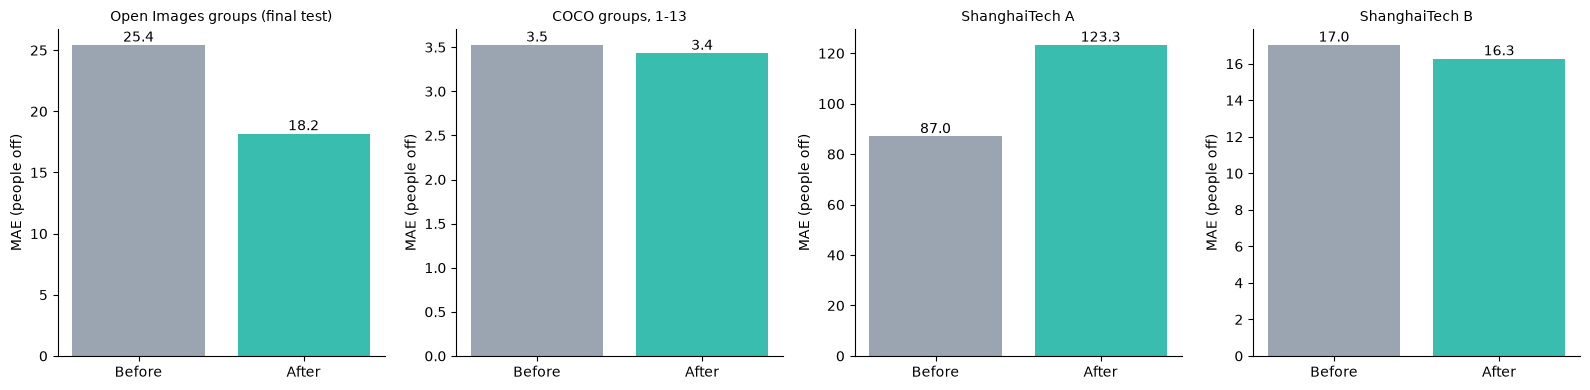

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (_, r) in zip(axes, results.iterrows()):
    bars = ax.bar(["Before", "After"], [r["Before MAE"], r["After MAE"]], color=["#9AA5B1", "#38BDAE"])
    ax.bar_label(bars, fmt="%.1f")
    ax.set_title(r["Set"], fontsize=10)
    ax.set_ylabel("MAE (people off)")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 5. The 26 final-test group photos, one by one (first version)

In [6]:
g = test[test["set"].str.startswith("Open Images")].copy()
g["error"] = g["after"] - g["true"]
print(g.sort_values("true")[["true", "before", "after", "error", "method"]].round(0).to_string(index=False))
print(f"\nMedian error: before {(g['before'] - g['true']).abs().median():.1f}, after {g['error'].abs().median():.1f} people")

 true  before  after  error   method
 14.0    10.0    9.0   -5.0 detector
 14.0    10.0   11.0   -3.0 detector
 14.0    11.0   17.0    3.0 detector
 15.0    10.0   10.0   -5.0 detector
 15.0     9.0   17.0    2.0 detector
 15.0    12.0   12.0   -3.0 detector
 15.0     9.0   14.0   -1.0 detector
 16.0    10.0    7.0   -9.0 detector
 16.0    99.0   99.0   83.0   street
 16.0    12.0   18.0    2.0 detector
 16.0    11.0   12.0   -4.0 detector
 17.0    15.0   20.0    3.0 detector
 17.0    47.0   47.0   30.0   street
 17.0    13.0   13.0   -4.0 detector
 18.0    14.0   16.0   -2.0 detector
 18.0    12.0   15.0   -3.0 detector
 19.0     2.0    2.0  -17.0 detector
 20.0    13.0   11.0   -9.0 detector
 21.0   134.0   24.0    3.0 detector
 21.0    19.0   22.0    1.0 detector
 22.0   237.0  237.0  215.0   street
 22.0    21.0   21.0   -1.0 detector
 22.0    18.0   20.0   -2.0 detector
 25.0    45.0   20.0   -5.0 detector
 25.0    70.0   70.0   45.0   street
 38.0    99.0   26.0  -12.0 detector



## 6. A problem the test caught, and the fix

The first version made **dense crowds much worse** (ShanghaiTech A: 87.0 → 123.3). In 8 packed-crowd photos the detector
found only a few faces, their boxes covered little of the photo, and the group check mistook the crowd for a group
(1,266 people counted as 17). None of the 45 validation crowds had shown this.

**Fix:** the Dense model's check now comes first. If it sees more than 250 people, the photo is a dense crowd, and the
group check isn't used. No number was tuned.

**This fix was made after looking at the test results, so the fixed numbers below are not a clean held-out score.**
To get an independent check on the failure, the fix is also run on the **255 ShanghaiTech A training photos**, which
played no part in choosing the group check or in spotting this problem.

## 7. The fixed version

In [7]:
fixed = [new_rule(p, dense_first=True) for p in test["path"]]
test["fixed"] = [o[0] for o in fixed]
test["fixed_method"] = [o[1] for o in fixed]

rows = []
for name, df in test.groupby("set", sort=False):
    b, f, a = score(df, "before"), score(df, "after"), score(df, "fixed")
    rows.append({"Set": name, "Photos": len(df), "Before MAE": b["MAE"], "First version MAE": f["MAE"], "Fixed MAE": a["MAE"],
                 "Change vs before %": (a["MAE"] - b["MAE"]) / b["MAE"] * 100, "Before bias": b["Bias"], "Fixed bias": a["Bias"],
                 "Before within 2 %": b["Within 2 %"], "Fixed within 2 %": a["Within 2 %"]})
fixed_results = pd.DataFrame(rows)
print(fixed_results.round(2).to_string(index=False))
g = test[test["set"].str.startswith("Open Images")]
print(f"\nOpen Images median error: before {(g['before'] - g['true']).abs().median():.1f}, fixed {(g['fixed'] - g['true']).abs().median():.1f} people")

                            Set  Photos  Before MAE  First version MAE  Fixed MAE  Change vs before %  Before bias  Fixed bias  Before within 2 %  Fixed within 2 %
Open Images groups (final test)      26       25.43              18.19      18.19              -28.49        18.28       11.65              11.54             26.92
              COCO groups, 1-13     150        3.53               3.43       3.43               -2.64         2.23        1.54              80.00             72.00
                 ShanghaiTech A     182       87.03             123.31      86.94               -0.10        -2.80       -2.71               1.65              1.65
                 ShanghaiTech B     316       17.03              16.28      16.28               -4.42        -0.44        0.84              12.03             15.51

Open Images median error: before 5.5, fixed 3.5 people


In [8]:
# Independent check on packed crowds: ShanghaiTech A training photos
img_dir = os.path.join("data", "shanghaitech", "ShanghaiTech", "part_A", "train_data", "images")
train_a = []
for n in sorted(os.listdir(img_dir), key=lambda n: int(n.split("_")[1].split(".")[0])):
    info = sio.loadmat(os.path.join("data", "shanghaitech", "ShanghaiTech", "part_A", "train_data", "ground-truth",
                                    "GT_" + n.replace(".jpg", ".mat")))["image_info"][0, 0][0, 0]
    train_a.append({"path": os.path.join(img_dir, n), "true": float(info[1][0, 0])})
perm = np.random.default_rng(42).permutation(len(train_a))
train_a = pd.DataFrame([train_a[i] for i in perm[int(round(0.15 * len(train_a))):]])   # the same 255 photos as training
train_a["before"] = [old_rule(p) for p in train_a["path"]]
first = [new_rule(p) for p in train_a["path"]]
last = [new_rule(p, dense_first=True) for p in train_a["path"]]
train_a["after"], train_a["fixed"] = [o[0] for o in first], [o[0] for o in last]
print(f"{len(train_a)} ShanghaiTech A training photos")
for col, label in [("before", "Before"), ("after", "First version"), ("fixed", "Fixed")]:
    print(f"  {label:14s} MAE {score(train_a, col)['MAE']:.1f}")
print("  Crowd photos handed to the detector: first version", sum(o[1] == "detector" for o in first), "| fixed", sum(o[1] == "detector" for o in last))

255 ShanghaiTech A training photos
  Before         MAE 67.0
  First version  MAE 107.4
  Fixed          MAE 66.8
  Crowd photos handed to the detector: first version 16 | fixed 4


## 8. Check: does the fixed version match the real app code?

In [9]:
sample = test.groupby("set", sort=False).sample(4, random_state=7)
mismatches = 0
for r in sample.itertuples():
    img, _ = cm.prepare_image(Image.open(r.path))
    real = cm.count_auto(img, models, detector)
    mismatches += not (real.method == r.fixed_method and abs(real.count - r.fixed) < 0.01)
print(f"{len(sample)} photos run through the real count_auto: {mismatches} mismatches")
assert mismatches == 0

16 photos run through the real count_auto: 0 mismatches


## 9. What this shows

| Photos | Before | First version | Fixed (in the app) |
|---|---|---|---|
| **Groups of 14–38 (Open Images, 26)** | 25.4 | 18.2 | **18.2** |
| Everyday groups of 1–13 (COCO, 150) | 3.53 | 3.43 | **3.43** |
| Dense crowds (ShanghaiTech A, 182) | 87.0 | 123.3 | **86.9** |
| Street crowds (ShanghaiTech B, 316) | 17.0 | 16.3 | **16.3** |

- **Larger groups improved:** the average error fell 28%, the typical (median) error went from 5.5 to 3.5 people, and counts within 2 people rose from 12% to 27%.
- **Still not good enough to call solved:** 3 of the 26 photos are still off by 30 or more (one group of 22 was counted as 237), because CSRNet's estimate is used there and the group check doesn't fire.
- **One trade-off:** on COCO the average error improved slightly, but counts within 2 people fell from 80% to 72%, because tiling sometimes adds or splits a person.
- **The fix came after seeing the test.** The Dense-first order was added because of the failure this test exposed, so the "Fixed" column is not a clean held-out score. The independent check on 255 ShanghaiTech A training photos agrees: 67.0 before, 107.4 for the first version, 66.8 fixed.
- **Small sample:** 26 test photos is few, and one bad photo moves the average a lot.
- **Not measured:** eye-level groups of 39–150 people. Open Images marks tightly packed people as a single "group" box, so no labelled photos of that size were available.